In [ ]:
import sys
sys.path.insert(0,'../CRLDenv/lib/python3.9/site-packages')
print(sys.path)

['../CRLDenv/lib/python3.9/site-packages', '/home/clemence/Documents/PhD/Code/DistRLdynamics', '/usr/lib/python39.zip', '/usr/lib/python3.9', '/usr/lib/python3.9/lib-dynload', '', '/home/clemence/Documents/PhD/Code/pyCRLD/CRLDenv/lib/python3.9/site-packages']


In [ ]:
from pyCRLD.Environments.DistTwoArmedBanditOneState import DistTwoArmedBanditOneState
from pyCRLD.Environments.RiskRewardDilemma import RiskRewardDilemma
from pyCRLD.Agents.StrategySARSA import stratSARSA
from qBaseDistR import qbaseDist
from qBaseSARSA import qbaseSARSA

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [ ]:
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)

In [ ]:
xs = np.array([[-1, 1],
               [-1, 1]])
ps = np.array([[0.3, 0.7],
               [0.7, 0.3]])
env = DistTwoArmedBanditOneState(disttype='discrete', xs=xs, ps=ps)

In [ ]:
def compute_discretization_grid(Rmin, # Minimum reward obtainable
                                Rmax, # Maximum reward obtainable
                                Nr # Number of bin
                                ) -> tuple: # Gridpoints, Width 
    gridpoints = np.linspace(Rmin, Rmax, Nr)
    width  = np.round(gridpoints[1] - gridpoints[0], 8)
    return gridpoints, width

def compute_Risjasr(env, # The env object
                    Rmin,
                    Rmax,
                    nr,  # The number of reward bins
                    discretization_sigma # Width of the discritization normal distribution
                   ) -> np.ndarray: # Reward distribution
    # get the discretization grid
    points, width = compute_discretization_grid(Rmin, Rmax, nr)

    # init the reward distribution tensor
    Risjasr = np.zeros(env.R.shape + (nr,))  # last dim is distrib

    # go through the reward tensor of the envrionment
    for index, _ in np.ndenumerate(env.R):
        if env.disttype == 'continuous':
            sigma = env.Rdict['scale'][index]
            loc = env.Rdict['loc'][index] 
            dist = env.Rdict['dist'][index]
    
            disp = dispatcher()
            func = disp[dist]
            
            for r in range(nr):
                if r==0: # first interval
                    prop = func.cdf(points[r]+width/2, loc, sigma)
                elif r==nr-1: # last interval
                    prop = 1 - func.cdf(points[r]-width/2, loc, sigma)
                else: # all other intervals
                    prop = func.cdf(points[r]+width/2, loc, sigma)\
                        - func.cdf(points[r]-width/2, loc, sigma)   
                Risjasr[index +(r,)] = prop
                
        elif env.disttype == None:  # not distributional
            loc = env.R[index]
            sigma = discretization_sigma
            func = stats.norm
            for r in range(nr):
                if r==0: # first interval
                    prop = func.cdf(points[r]+width/2, loc, sigma)
                elif r==nr-1: # last interval
                    prop = 1 - func.cdf(points[r]-width/2, loc, sigma)
                else: # all other intervals
                    prop = func.cdf(points[r]+width/2, loc, sigma)\
                        - func.cdf(points[r]-width/2, loc, sigma)   
                Risjasr[index +(r,)] = prop
        
        else:  # discrete
            x = env.Rdict['x'][index]
            p = env.Rdict['p'][index]
            sigma = discretization_sigma
            func = stats.norm
            for i in range(len(x)):
                for r in range(nr):
                    if r==0: # first interval
                        prop = p[i] * func.cdf(points[r]+width/2, x[i], sigma)
                    elif r==nr-1: # last interval
                        prop = p[i] * (1 - func.cdf(points[r]-width/2, x[i], sigma))
                    else: # all other intervals
                        prop = p[i] * (func.cdf(points[r]+width/2, x[i], sigma)\
                                       - func.cdf(points[r]-width/2, x[i], sigma))   
                    Risjasr[index +(r,)] += prop

    return Risjasr

In [ ]:
nr = 29
sig = 0.05
Rmin = -0.5
Rmax = 2
Risjasr = compute_Risjasr(env, Rmin, Rmax, nr, sig)
gpoints, wdth = compute_discretization_grid(Rmin, Rmax, nr)

def plot_Risjasr(Rr=Risjasr,gpoints=gpoints,wdth=wdth):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    for i, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Rr[0,0,i,0], width=0.92*wdth, color='k')
        ax.set_xlabel(r'$r$')
    axes[0].set_ylabel(r'$R_{0a0}(r)$')
    axes[0].set_title(r'$R_{psp}(r)$')
    axes[1].set_title(r'$R_{prp}(r)$')

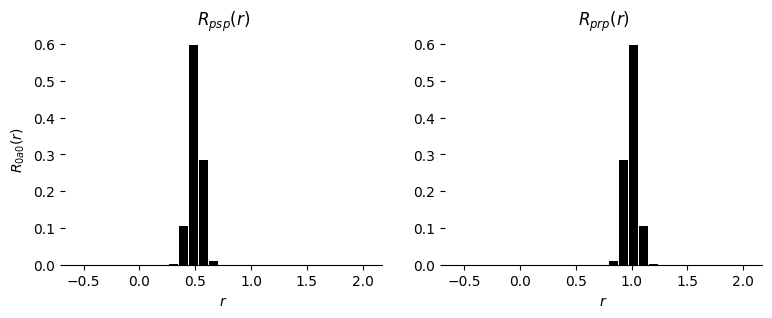

In [ ]:
plot_Risjasr(Rr=Risjasr, gpoints=gpoints, wdth=wdth)

In [ ]:
qb = qbaseSARSA(env,
               nr_reward_bins=29,
               discretization_sigma=0.05,
               learning_rates=0.1,
               discount_factors=0.9,
               Rmin=-0.5,
               Rmax=2)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [ ]:
X = 0.5 * np.ones((1, 2, 2))
# X[0, 0, 0] = 0.8
# X[0, 0, 1] = 1 - X[0, 0, 0]

In [ ]:
Risr = qb.Risr(X)

def plot_Risr(Rr=Risr,gpoints=gpoints,wdth=wdth):
    fig, ax = plt.subplots(1, 1, figsize=(5, 3))
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(gpoints, Rr[0,0,:], width=0.92*wdth, color='k')
    ax.set_xlabel(r'$r$')
    ax.set_ylabel(r'$R_{0p}(r)$')
    ax.set_title(r'$R_{0p}(r)$')

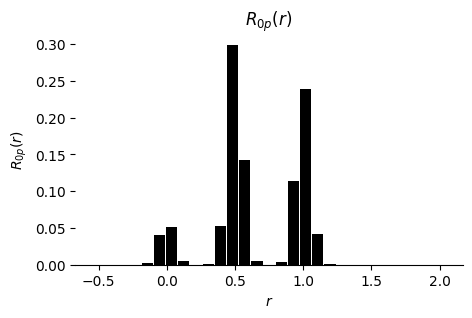

In [ ]:
plot_Risr(Rr=Risr,gpoints=gpoints,wdth=wdth)

In [ ]:
Risar = qb.Risar(X)

def plot_Risar(Rr=Risar,gpoints=gpoints,wdth=wdth):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    for i, ax in enumerate(axes):
        ax.spines[['right', 'top', 'left']].set_visible(False)
        ax.bar(gpoints, Rr[0,0,i,:], width=0.92*wdth, color='k')
        ax.set_xlabel(r'$r$')
    axes[0].set_ylabel(r'$R_{0a}(r)$')
    axes[0].set_title(r'$R_{ps}(r)$')
    axes[1].set_title(r'$R_{pr}(r)$')

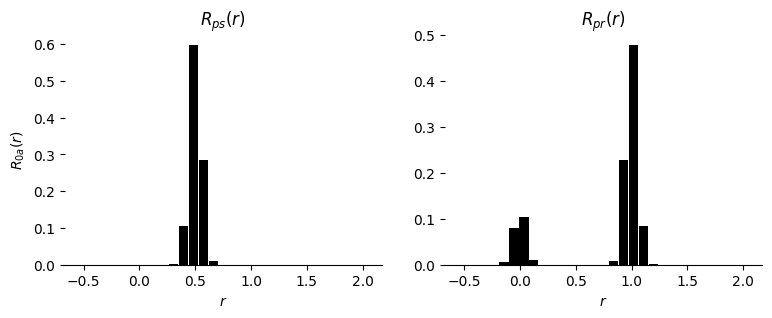

In [ ]:
plot_Risar(Rr=Risar,gpoints=gpoints,wdth=wdth)

In [ ]:
Visv = qb.Visv(X)

def plot_Visv(Vv=Visv,gpoints=gpoints,wdth=wdth):
    fig, ax = plt.subplots(1, 1, figsize=(5, 3))
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(gpoints, Vv[0,0,:], width=0.92*wdth, color='k')
    ax.set_xlabel(r'$v$')
    ax.set_ylabel(r'$V_{0}(v)$')
    ax.set_title(r'$V_{0}(v)$')

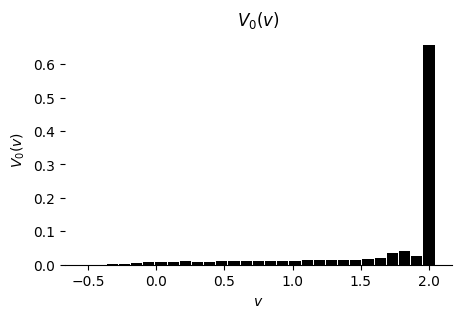

In [ ]:
plot_Visv(Vv=Visv,gpoints=gpoints,wdth=wdth)

In [ ]:
nr=17
Rmin=-0.5
Rmax=1.5

In [ ]:
qb = qbaseSARSA(env,
                nr_reward_bins=nr,
                discretization_sigma=0.05,
                learning_rates=0.1,
                discount_factors=0.4,
                Rmin=Rmin,
                Rmax=Rmax,
                use_prefactor=True,
                method='weights',
                wU=3)

In [ ]:
gpoints, wdth = compute_discretization_grid(Rmin, Rmax, nr)

In [ ]:
Risar = qb.Risar(X)

def plot_Risar(Rr=Risar,gpoints=gpoints,wdth=wdth,save=False):
    fig, ax = plt.subplots(1, 1, figsize=(3, 2))
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(gpoints, Rr[0,0,1,:], width=0.92*wdth, color='mediumseagreen', alpha=1)
    mR = np.dot(gpoints, Rr[0,0,1,:])
    ax.plot([mR, mR], [0.0, 0.105], c='k', lw=4)
    ax.set_xlabel(r'$r$')
    #ax.set_ylim([0, 0.8])
    ax.set_ylabel(r'$R_{p,risky}(r)$')
    #ax.set_title("Reward distribution in current state")
    if save==True:
        ax.figure.savefig("_figs/Risar.png", dpi=300, bbox_inches='tight')

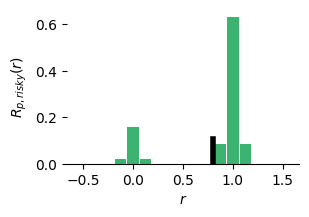

In [ ]:
plot_Risar(Rr=Risar,gpoints=gpoints,wdth=wdth,save=True)

In [ ]:
NextQisaq = qb.NextQisaq(X)

def plot_nextQisaq(Qq=NextQisaq,gpoints=gpoints,wdth=wdth, save=False):
    fig, ax = plt.subplots(1, 1, figsize=(3, 2))
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(gpoints, Qq[0,0,1,:], width=0.9*wdth, color='mediumpurple', alpha=1)
    mNQ = np.dot(gpoints, Qq[0,0,1,:])
    ax.plot([mNQ, mNQ], [0.0, 0.04], c='k', lw=4)
    ax.set_xlabel(r'$q$')
    #ax.set_ylim([0, 0.25])
    ax.set_ylabel(r'$^{next}Q_{p,risky}(q)$')
    #ax.set_title("Next-state Q-value distribution")
    if save==True:
        ax.figure.savefig("_figs/nextQisaq.png", dpi=300, bbox_inches='tight')

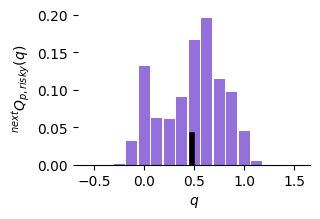

In [ ]:
plot_nextQisaq(Qq=NextQisaq,gpoints=gpoints,wdth=wdth, save=True)

In [ ]:
NextQisaq[0, 0, 0, :]

Array([0.17840952, 0.02145059, 0.02163476, 0.01945529, 0.01810192,
       0.01952067, 0.0225004 , 0.02716572, 0.03737894, 0.04742796,
       0.04319312, 0.03098461, 0.02555268, 0.03098463, 0.04319317,
       0.047428  , 0.03737895, 0.0271657 , 0.02250037, 0.01952065,
       0.01810192, 0.01945531, 0.02163479, 0.02145063, 0.17840967],      dtype=float32)

In [ ]:
Qisaq = qb.Qisaq(X)

def plot_Qisaq(Qq=Qisaq,gpoints=gpoints,wdth=wdth, save=False):
    fig, ax = plt.subplots(1, 1, figsize=(3, 2))
    ax.spines[['right', 'top', 'left']].set_visible(False)
    ax.bar(gpoints, Qq[0,0,1,:], width=0.9*wdth, color='goldenrod', alpha=1)
    mQ = np.dot(gpoints, Qq[0,0,1,:])
    ax.plot([mQ, mQ], [0.0, 0.05], c='k', lw=4)
    ax.set_xlabel(r'$q$')
    #ax.set_ylim([0, 0.35])
    ax.set_ylabel(r'$Q_{p,risky}(q)$')
    #ax.set_title("Q-value distribution in current state")
    if save==True:
        ax.figure.savefig("_figs/Qisaq.png", dpi=300, bbox_inches='tight')

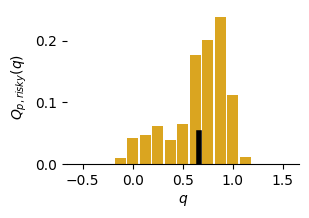

In [ ]:
plot_Qisaq(Qq=Qisaq,gpoints=gpoints,wdth=wdth, save=True)

In [ ]:
from Methods import weights

In [ ]:
Qis = qb.Qis(X)
Qisa = np.repeat(Qis[..., np.newaxis], qb.M, axis=-1)
w = np.ones((qb.N, qb.Z, qb.M, len(gpoints)))
n = np.newaxis
upper = gpoints[n,n,n,:] >= Qisa[:,:,:,n]
upper = upper * (qb.wU - 1)
w = w + upper
new_dist = weights(w, Qisaq, gpoints)

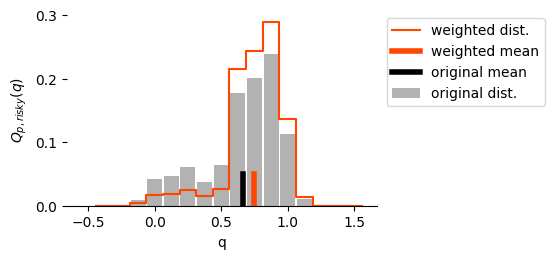

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(4,2.5))
ax.spines[['right', 'top', 'left']].set_visible(False)
ax.bar(gpoints, Qisaq[0,0,1,:], width=0.9*wdth, color='k', alpha=0.3, 
       label='original dist.')
ax.step(gpoints+wdth/2, new_dist[0,0,1,:], color='orangered', label='weighted dist.')
mQ = np.dot(gpoints, Qisaq[0,0,1,:])
mwQ = np.dot(gpoints, new_dist[0,0,1,:])
ax.plot([mwQ, mwQ], [0.0, 0.05], c='orangered', lw=4, label='weighted mean')
ax.plot([mQ, mQ], [0.0, 0.05], c='k', lw=4, label='original mean')
ax.set_xlabel("q")
#ax.set_ylim([0, 0.35])
ax.legend(bbox_to_anchor=(1.01, 1.01))
ax.set_ylabel(r'$Q_{p,risky}(q)$')
#ax.set_title("optimistic estimate of the Q-value")
ax.figure.savefig("_figs/weighted_dist.png", dpi=300, bbox_inches='tight')

In [ ]:
np.dot(qb.gridpoints, Qisaq[0, 0, 0])

0.6331633481895551

In [ ]:
np.dot(qb.gridpoints, Qisaq[0, 0, 1])

0.01879129884764552

In [ ]:
0.8*0.4

0.32000000000000006

In [ ]:
0.2*-0.4

-0.08000000000000002